#### Configuration
Compare gain operators and actuation intervals; the saved Qwen3-4B run opens without models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from extensions.experiments import Sweep, generate_run, judge_run

RUN = False
config = Sweep(
    notebook='02_qwen3_model_ablation', model_name='Qwen/Qwen3-4B',
    concept='football', prompt='Once upon a time', trials=100,
    lambdas=(0.5, 1., 1.5, 2., 2.5, 3., 3.5, 4.),
    r_values=(10.,), q=0.1, qf=0.1, last_n=(None,), every=(1, 2, 3, 4),
    operators=('Identity', 'Mean Jacobian', 'Random'), drift_weights=(0.,),
    seed=0, random_seed=0, direction_samples=200, jacobian_samples=50,
    max_ctx=32, direction_batch=8, max_new_tokens=96, temperature=0.7, top_p=0.95,
    generation_batch=100, trace_batch=100, judge_batch=128, judge_chunk=2048,
    dtype='auto', device_map='auto',
)
RUN_DIR = config.run_dir

#### Generate
RUN builds missing model-specific caches and resumes completed conditions.

In [2]:
if RUN:
    generate_run(config)

#### Judge and load
Judging resumes from saved completions; reviewing loads only the small summary CSV.

In [3]:
if RUN:
    judge_run(config)
summary = pd.read_csv(RUN_DIR / 'summary.csv')
selected = summary.loc[summary.operator.isin(config.operators) & summary.every.isin(config.every)
                       & summary['lambda'].isin(config.lambdas) & summary.R.isin(config.r_values)]

#### Summary
The best on-concept-and-coherent setting for each operator and interval.

In [4]:
best = selected.loc[selected.groupby(['every', 'operator'])['both'].idxmax()]
display(best[['every', 'operator', 'lambda', 'concept', 'coherent', 'both', 'n']].round(3))

,every,operator,lambda,concept,coherent,both,n
8,1,Identity,4.0,0.93,0.81,0.77,100
13,1,Mean Jacobian,2.5,0.90,0.69,0.65,100
23,1,Random,3.5,0.97,0.76,0.76,100
32,2,Identity,4.0,0.53,0.89,0.44,100
38,2,Mean Jacobian,3.0,0.67,0.78,0.53,100
48,2,Random,4.0,0.88,0.81,0.72,100
56,3,Identity,4.0,0.26,0.95,0.26,100
64,3,Mean Jacobian,4.0,0.89,0.68,0.63,100
72,3,Random,4.0,0.57,0.86,0.48,100
80,4,Identity,4.0,0.16,0.98,0.15,100


#### Coherence versus concept
One panel per actuation interval; error bars are one binomial standard error.

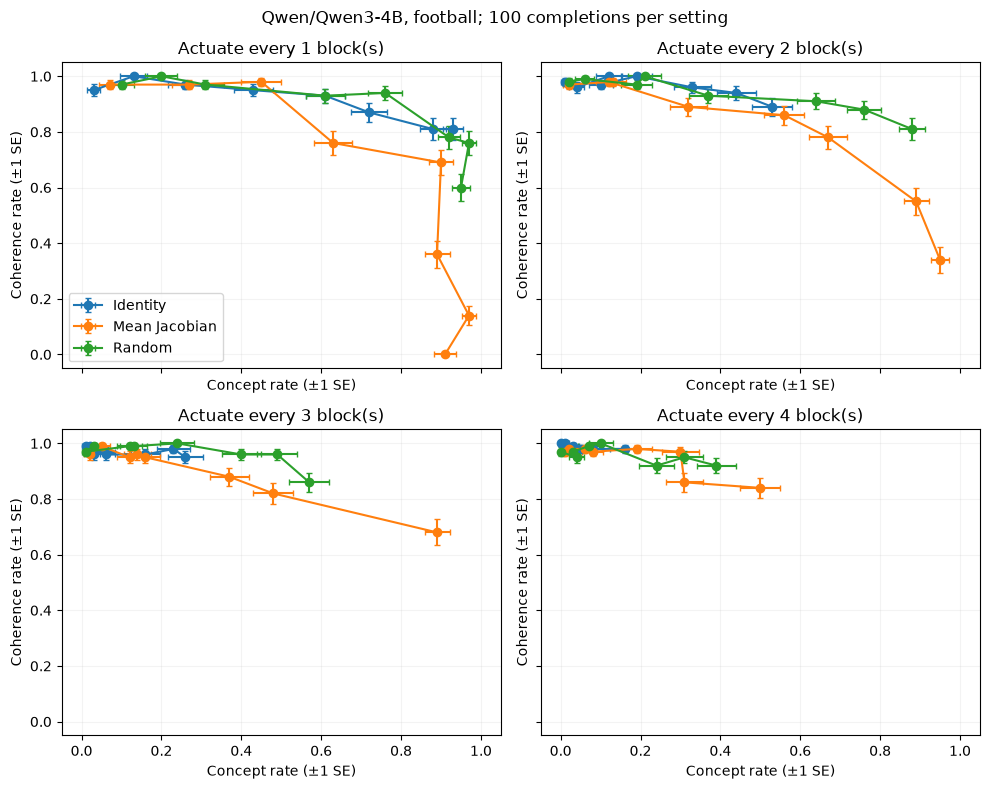

In [5]:
columns = min(2, len(config.every))
rows = (len(config.every) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4 * rows),
                         sharex=True, sharey=True, squeeze=False)
for ax, every in zip(axes.flat, config.every):
    for name in config.operators:
        curve = selected.loc[selected.every.eq(every) & selected.operator.eq(name)].sort_values('lambda')
        ax.errorbar(curve.concept, curve.coherent, xerr=curve.concept_se,
                    yerr=curve.coherent_se, marker='o', capsize=2, label=name)
    ax.set(title=f'Actuate every {every} block(s)', xlabel='Concept rate (±1 SE)',
           ylabel='Coherence rate (±1 SE)', xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
    ax.grid(alpha=0.15)
for ax in list(axes.flat)[len(config.every):]:
    ax.set_visible(False)
axes.flat[0].legend()
fig.suptitle(f'{config.model_name}, {config.concept}; {config.trials} completions per setting')
fig.tight_layout()
fig.savefig(RUN_DIR / f'ablation_{config.concept}.png', dpi=150)
plt.show()

In [6]:
peaks = selected.groupby('operator')['both'].max()
numbers = ', '.join(f'{name}: {rate:.1%}' for name, rate in peaks.items())
display(Markdown(f'#### Result\nPeak on-concept-and-coherent rates across the displayed grid: {numbers}. '
                 'These are maxima over settings, not matched-concept comparisons.'))

#### Result
Peak on-concept-and-coherent rates across the displayed grid: Identity: 77.0%, Mean Jacobian: 65.0%, Random: 76.0%. These are maxima over settings, not matched-concept comparisons.